In [1]:
#Importing - numpy, matplotlib, scipy for the questions
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
np.random.seed(42)
print('Setup complete. NumPy', np.__version__)

Setup complete. NumPy 2.1.3


In [2]:
#probability simulation-P(A):1(A)
rolls = np.random.randint(1, 7, size=100_000)
p_even = (rolls % 2 == 0).mean()
p_gt4  = (rolls > 4).mean()
print('P(even) ~', round(p_even, 3), ' (true 0.5)')
print('P(>4)   ~', round(p_gt4, 3),  ' (true 0.333)')

P(even) ~ 0.502  (true 0.5)
P(>4)   ~ 0.334  (true 0.333)


In [3]:
#(Disjoint events)-Addition Rule: it's either 1 or 2 ,can not be both the events:1(B)
p_1 = (rolls == 1).mean()
p_2 = (rolls == 2).mean()
p_1_or_2 = (np.isin(rolls, [1, 2])).mean()
print('P(1) + P(2) =', round(p_1 + p_2, 3))
print('P(1 or 2)   =', round(p_1_or_2, 3), ' -> they match')

P(1) + P(2) = 0.334
P(1 or 2)   = 0.334  -> they match


In [6]:
#1-EX :
import numpy as np
flips = np.random.randint(0, 2, size=(100_000, 2))   # 100k pairs of flips
heads = flips.sum(axis=1)
p0 = np.mean(heads == 0)
p1 = np.mean(heads == 1)
p2 = np.mean(heads == 2)
print(f"P(both heads)      ≈ {p2:.4f}  (theory 0.25)")
print(f"P(at least 1 head) ≈ {np.mean(heads >= 1):.4f}  (theory 0.75)")
print(f"P(0)={p0:.4f}, P(1)= {p1:.4f}, P(2)={p2:.4f}")
print(f"Sum = {p0 + p1 + p2}")

P(both heads)      ≈ 0.2490  (theory 0.25)
P(at least 1 head) ≈ 0.7495  (theory 0.75)
P(0)=0.2505, P(1)= 0.5004, P(2)=0.2490
Sum = 1.0


In [7]:
#Ex-2(A): CONDITIONAL PROBABILITY  P(A | B) = P(A and B) / P(B)
rolls = np.random.randint(1, 7, size=100_000)
even = rolls[rolls % 2 == 0]
p_6_given_even = (even == 6).mean()
print('P(6 | even) ~', round(p_6_given_even, 3), ' (true 1/3)')

P(6 | even) ~ 0.331  (true 1/3)


In [8]:
#Ex-2(B):idependence checking
A = rolls > 3
B = rolls % 2 == 0
p_A        = A.mean()
p_A_given_B = A[B].mean()
print('P(A)      =', round(p_A, 3))
print('P(A | B)  =', round(p_A_given_B, 3))
print('Independent?', np.isclose(p_A, p_A_given_B, atol=0.02))

P(A)      = 0.501
P(A | B)  = 0.669
Independent? False


In [9]:
#Ex-2:Conditional probability and independence
import numpy as np
rolls = np.random.randint(1, 7, size=100_000)   # fresh rolls
odd = rolls % 2 == 1
lt4 = rolls < 4
p_odd_given_lt4 = odd[lt4].mean()      # condition on roll < 4
p_lt4 = lt4.mean()
p_odd = odd.mean()
p_joint = (odd & lt4).mean()
print(f"P(odd | <4) ≈ {p_odd_given_lt4:.4f}  (theory 0.6667)")
print(f"P(roll < 4) ≈ {p_lt4:.4f}  (theory 0.5)")
print(f"P(odd)      ≈ {p_odd:.4f}  (theory 0.5)")
print(f"P(odd ∩ <4) ≈ {p_joint:.4f} vs P(odd)·P(<4) ≈ {p_odd * p_lt4:.4f}")

P(odd | <4) ≈ 0.6670  (theory 0.6667)
P(roll < 4) ≈ 0.5000  (theory 0.5)
P(odd)      ≈ 0.4995  (theory 0.5)
P(odd ∩ <4) ≈ 0.3335 vs P(odd)·P(<4) ≈ 0.2497


In [10]:
#3(A):medical-test problem
p_disease   = 0.01
p_pos_given_D  = 0.99
p_pos_given_nD = 0.01
p_pos = p_pos_given_D * p_disease + p_pos_given_nD * (1 - p_disease)
p_D_given_pos = (p_pos_given_D * p_disease) / p_pos
print('P(sick | positive test) =', round(p_D_given_pos, 3))
print('-> only ~50%, because the disease is rare (base-rate effect)')

P(sick | positive test) = 0.5
-> only ~50%, because the disease is rare (base-rate effect)


In [11]:
#3(B). the same answer by simulation (sanity check)
N = 1_000_000
has_disease = np.random.rand(N) < p_disease
tests_pos = np.where(has_disease,
                     np.random.rand(N) < p_pos_given_D,
                     np.random.rand(N) < p_pos_given_nD)

among_positive = has_disease[tests_pos]
print('Simulated P(sick | positive) =', round(among_positive.mean(), 3))

Simulated P(sick | positive) = 0.496


In [12]:
#EX 3 — A Bayes scenario
# 1. priors / likelihoods
p_spam = 0.20                    # prior
p_free_given_spam = 0.60         # likelihood
p_free_given_ham  = 0.05         # false-positive rate
p_ham = 1 - p_spam               # 0.80

# 2. P('free') via total probability
p_free = p_free_given_spam * p_spam + p_free_given_ham * p_ham

# 3. Bayes: P(spam | 'free')
p_spam_given_free = p_free_given_spam * p_spam / p_free

print(f"P('free')        = {p_free:.4f}")
print(f"P(spam | 'free') = {p_spam_given_free:.4f}")

P('free')        = 0.1600
P(spam | 'free') = 0.7500


In [13]:
#4A. BERNOULLI & POISSON (discrete)
# Bernoulli: a single yes/no trial with probability p
bern = stats.bernoulli(p=0.3).rvs(size=10_000)
print('Bernoulli(0.3) mean ~', round(bern.mean(), 3), '(true 0.3)')

# Poisson: count of events per interval, rate lambda
pois = stats.poisson(mu=4).rvs(size=10_000)
print('Poisson(4) mean ~', round(pois.mean(), 3), '(true 4)')

Bernoulli(0.3) mean ~ 0.294 (true 0.3)
Poisson(4) mean ~ 4.011 (true 4)


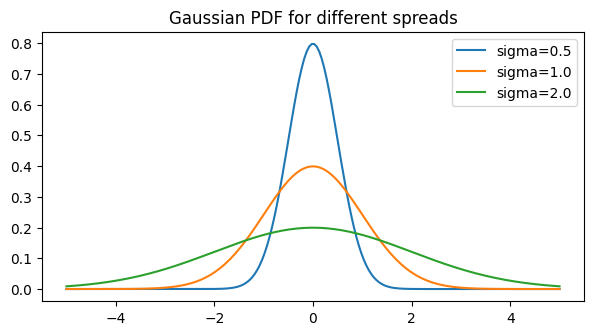

In [17]:
# 4B. THE GAUSSIAN (normal) — plot the bell curve
x = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
for sigma in [0.5, 1.0, 2.0]:
    ax.plot(x, stats.norm(0, sigma).pdf(x), label=f'sigma={sigma}')
ax.set_title('Gaussian PDF for different spreads'); ax.legend(); plt.show()

Sample mean ≈ 2.0068  (theory 2)
Sample var  ≈ 1.9810  (theory 2)


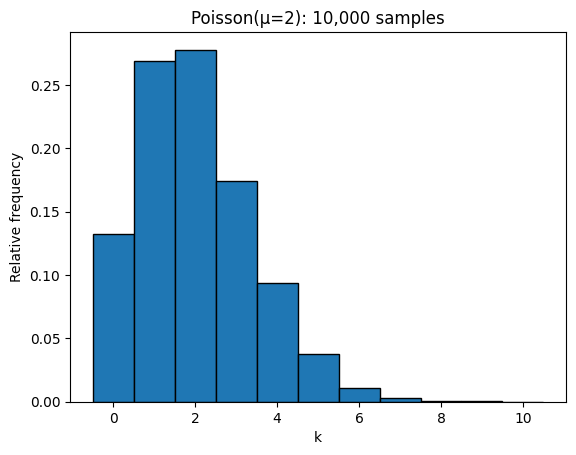

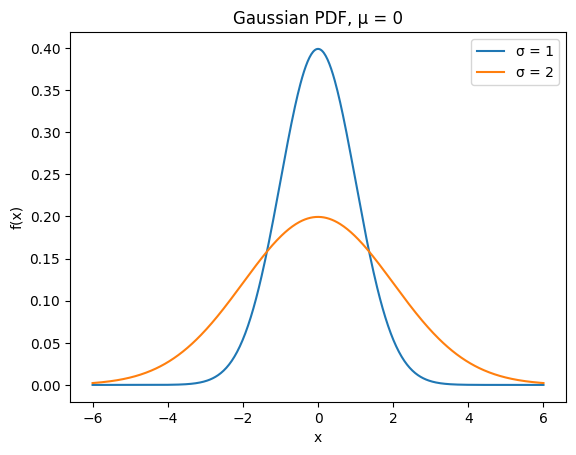

In [19]:
#4:Simulation & plot distributions
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Poisson(mu=2) samples + mean
samples = np.random.poisson(lam=2, size=10_000)
print(f"Sample mean ≈ {samples.mean():.4f}  (theory 2)")
print(f"Sample var  ≈ {samples.var():.4f}  (theory 2)")

# 2. histogram of the samples
plt.figure()
plt.hist(samples, bins=np.arange(samples.max() + 2) - 0.5,
         density=True, edgecolor="black")
plt.xlabel("k"); plt.ylabel("Relative frequency")
plt.title("Poisson(μ=2): 10,000 samples")
plt.show()

# 3. Gaussian PDF for two sigmas on one plot
x = np.linspace(-6, 6, 500)
plt.figure()
plt.plot(x, norm.pdf(x, loc=0, scale=1), label="σ = 1")
plt.plot(x, norm.pdf(x, loc=0, scale=2), label="σ = 2")
plt.xlabel("x"); plt.ylabel("f(x)")
plt.title("Gaussian PDF, μ = 0")
plt.legend()
plt.show()

In [18]:
#5. Entropy, KL divergence & mutual information
#5(A): entropy
from scipy.stats import entropy
fair   = [0.5, 0.5]
biased = [0.9, 0.1]
certain= [1.0, 0.0]
print('Entropy fair coin   :', round(entropy(fair, base=2), 3), 'bits')
print('Entropy biased coin :', round(entropy(biased, base=2), 3), 'bits')
print('Entropy certain     :', round(entropy(certain, base=2), 3), 'bits')

Entropy fair coin   : 1.0 bits
Entropy biased coin : 0.469 bits
Entropy certain     : 0.0 bits


In [20]:
#5B. KL DIVERGENCE — how far is Q from P?
P = np.array([0.5, 0.5])
Q = np.array([0.9, 0.1])
# scipy's entropy(P, Q) computes the KL divergence D(P || Q)
print('D(P || Q) =', round(entropy(P, Q, base=2), 3), 'bits')
print('D(P || P) =', round(entropy(P, P, base=2), 3), '-> zero (identical)')
print('Note: D(P||Q) != D(Q||P)  ->', round(entropy(Q, P, base=2), 3), '(not symmetric)')

D(P || Q) = 0.737 bits
D(P || P) = 0.0 -> zero (identical)
Note: D(P||Q) != D(Q||P)  -> 0.531 (not symmetric)


In [21]:
#5(C). MUTUAL INFORMATION
from sklearn.feature_selection import mutual_info_classif
from sklearn.datasets import load_iris
iris = load_iris()
mi = mutual_info_classif(iris.data, iris.target, random_state=0)
for name, score in sorted(zip(iris.feature_names, mi), key=lambda t: -t[1]):
    print(f'{score:.3f}  {name}')
print('-> higher MI = the feature tells us more about the class')

0.990  petal length (cm)
0.975  petal width (cm)
0.474  sepal length (cm)
0.286  sepal width (cm)
-> higher MI = the feature tells us more about the class


In [22]:
# 1. Entropy (bits) of fair 4- and 6-sided dice
H4 = entropy([1/4]*4, base=2)
H6 = entropy([1/6]*6, base=2)
print(f"H(4-sided) = {H4:.4f} bits")
print(f"H(6-sided) = {H6:.4f} bits")

# 2. KL divergence D(P || Q) in bits
P = np.array([0.7, 0.3]); Q = np.array([0.5, 0.5])
kl = entropy(P, Q, base=2)                 # same as np.sum(P*np.log2(P/Q))
print(f"D(P||Q) = {kl:.4f} bits")

# 3. Most / least informative iris feature (rerun if 5C vars are gone)
from sklearn.datasets import load_iris
from sklearn.feature_selection import mutual_info_classif
iris = load_iris()
mi = mutual_info_classif(iris.data, iris.target, random_state=0)
for name, s in zip(iris.feature_names, mi):
    print(f"{name:20s} {s:.3f}")
print("Most informative :", iris.feature_names[mi.argmax()])
print("Least informative:", iris.feature_names[mi.argmin()])

H(4-sided) = 2.0000 bits
H(6-sided) = 2.5850 bits
D(P||Q) = 0.1187 bits
sepal length (cm)    0.474
sepal width (cm)     0.286
petal length (cm)    0.990
petal width (cm)     0.975
Most informative : petal length (cm)
Least informative: sepal width (cm)
